In [15]:
import pandas as pd
df = pd.read_csv('social_media_engagement_5000.csv')
print("Initial Data Types:")
print(df.dtypes)
if 'post_date' in df.columns:
    df['post_date'] = pd.to_datetime(df['post_date'])
if 'likes' in df.columns and 'comments' in df.columns:
    likes_array = df['likes'].to_numpy()
    comments_array = df['comments'].to_numpy()
    total_interactions = np.add(likes_array, comments_array)
    print(f"\nMean interactions calculated via NumPy: {np.mean(total_interactions):.2f}")

Initial Data Types:
user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

Mean interactions calculated via NumPy: nan


In [16]:
# 1. Detect missing values
print("Missing values per column:\n", df.isnull().sum())

# 2. Handle missing data
# Fill numerical columns with median, categorical with mode, or drop if critical
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else "Unknown")

# 3. Duplicate Handling
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# 4. Data Formatting & Standardization (e.g., gender labels)
if 'gender' in df.columns:
    df['gender'] = df['gender'].astype(str).str.lower().str.strip()
    df['gender'] = df['gender'].replace({'m': 'male', 'f': 'female'})

# Correct unrealistic negative values in engagement metrics
for col in ['likes', 'comments', 'shares', 'impressions']:
    if col in df.columns:
        df[col] = df[col].abs()

# 5. Feature Cleaning & Extraction
if 'hashtags' in df.columns:
    # Count hashtags based on '#' symbols or comma separations
    df['hashtag_count'] = df['hashtags'].astype(str).apply(lambda x: len([h for h in x.split(',') if h.strip() != '']))

if 'sentiment' in df.columns:
    df['sentiment'] = df['sentiment'].astype(str).str.lower().str.strip()

Missing values per column:
 user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64
Removed 0 duplicate rows.


C:\Users\ACER\AppData\Local\Temp\ipykernel_19504\2940496780.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=['object']).columns


In [17]:
# 1. View structure & info
print("--- Head ---")
display(df.head())
print("\n--- Shape ---")
print(df.shape)
print("\n--- Info ---")
df.info()

# 2. Summary statistics
print("\n--- Summary Statistics ---")
display(df.describe())

# 3. Categorical distributions
for col in ['post_type', 'country', 'sentiment']:
    if col in df.columns:
        print(f"\nValue counts for {col}:")
        display(df[col].value_counts())

# 4. Correlation matrix for numeric fields
print("\n--- Correlation Matrix ---")
corr_matrix = df.select_dtypes(include=[np.number]).corr()
display(corr_matrix)

# 5. Groupby summaries
if 'post_type' in df.columns and 'likes' in df.columns:
    print("\n--- Average Likes by Post Type ---")
    display(df.groupby('post_type')['likes'].mean())

if 'country' in df.columns and 'impressions' in df.columns:
    print("\n--- Average Impressions by Country ---")
    display(df.groupby('country')['impressions'].mean())

--- Head ---


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862,1
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195,1
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372,1



--- Shape ---
(5000, 20)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               5000 non-null   float64
 2   gender            5000 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             5000 non-null   float64
 8   comments          5000 non-null   float64
 9   shares            5000 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment    

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0
mean,54561.890800,38.440400,548042.909000,10106.997400,1502.039800,1002.9106,4014.503200,50013.732800,393698.224800,0.964356,1.0
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,230927.884535,5.318029,0.0
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,87.000000,0.006363,1.0
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,194480.000000,0.145781,1.0
50%,54374.500000,38.000000,548077.500000,10105.500000,1497.000000,1012.0000,4034.500000,49934.500000,388982.000000,0.253896,1.0
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,589744.250000,0.504794,1.0
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,799533.000000,191.504348,1.0



Value counts for post_type:


post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

... (4 outputs left out)


--- Correlation Matrix ---


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,NaN
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,NaN
post_id,0.020051,-0.013153,1.000000,0.014526,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,NaN
likes,0.025811,-0.036322,0.014526,1.000000,-0.018421,0.004712,0.008710,0.007952,-0.022982,0.093520,NaN
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,NaN
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,NaN
watch_time_sec,-0.016847,0.005542,0.018374,0.008710,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,NaN
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,NaN
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,NaN
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,NaN



--- Average Likes by Post Type ---


post_type
image    10104.865277
reel     10037.802416
text     10100.148193
video    10188.600000
Name: likes, dtype: float64

In [19]:
# 1. Create new fields
if {'likes', 'comments', 'shares', 'impressions'}.issubset(df.columns):
    # Calculate a custom engagement score
    df['engagement_score'] = (df['likes'] * 1) + (df['comments'] * 2) + (df['shares'] * 3)
    
    # Log-transformed metrics to handle skewed distributions
    df['log_impressions'] = np.log1p(df['impressions'])
    df['log_likes'] = np.log1p(df['likes'])

# 2. Perform advanced groupby summaries
if {'post_type', 'country', 'engagement_score'}.issubset(df.columns):
    print("--- Groupby Summary: Post Type & Country ---")
    advanced_group = df.groupby(['post_type', 'country'])['engagement_score'].mean().unstack(fill_value=0)
    display(advanced_group)

In [20]:
stats_metrics = ['likes', 'comments', 'shares', 'watch_time', 'engagement_rate', 'followers']
available_stats = [m for m in stats_metrics if m in df.columns]

summary_records = []
for col in available_stats:
    series = df[col].dropna()
    summary_records.append({
        'Metric': col,
        'Mean': series.mean(),
        'Median': series.median(),
        'Mode': series.mode().iloc[0] if not series.mode().empty else np.nan,
        'Std Dev': series.std(),
        'Variance': series.var(),
        '25th Percentile': series.quantile(0.25),
        '50th Percentile (Median)': series.quantile(0.50),
        '75th Percentile': series.quantile(0.75),
        'Skewness': series.skew(),
        'Kurtosis': series.kurtosis()
    })

stats_df = pd.DataFrame(summary_records).set_index('Metric')
print("--- Detailed Statistical Analysis ---")
display(stats_df)

--- Detailed Statistical Analysis ---


,Mean,Median,Mode,Std Dev,Variance,25th Percentile,50th Percentile (Median),75th Percentile,Skewness,Kurtosis
Metric,,,,,,,,,,
likes,10106.997400,10105.500000,10105.500000,5702.293017,3.251615e+07,5235.000000,10105.500000,14959.000000,-0.006894,-1.149992
comments,1502.039800,1497.000000,1497.000000,856.393312,7.334095e+05,792.000000,1497.000000,2235.250000,0.003802,-1.144375
shares,1002.910600,1012.000000,1012.000000,570.855200,3.258757e+05,511.000000,1012.000000,1483.000000,-0.014654,-1.146857
engagement_rate,0.964356,0.253896,0.006363,5.318029,2.828143e+01,0.145781,0.253896,0.504794,18.781271,482.991739


C:\Users\ACER\AppData\Local\Temp\ipykernel_19504\176891960.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='orange'))


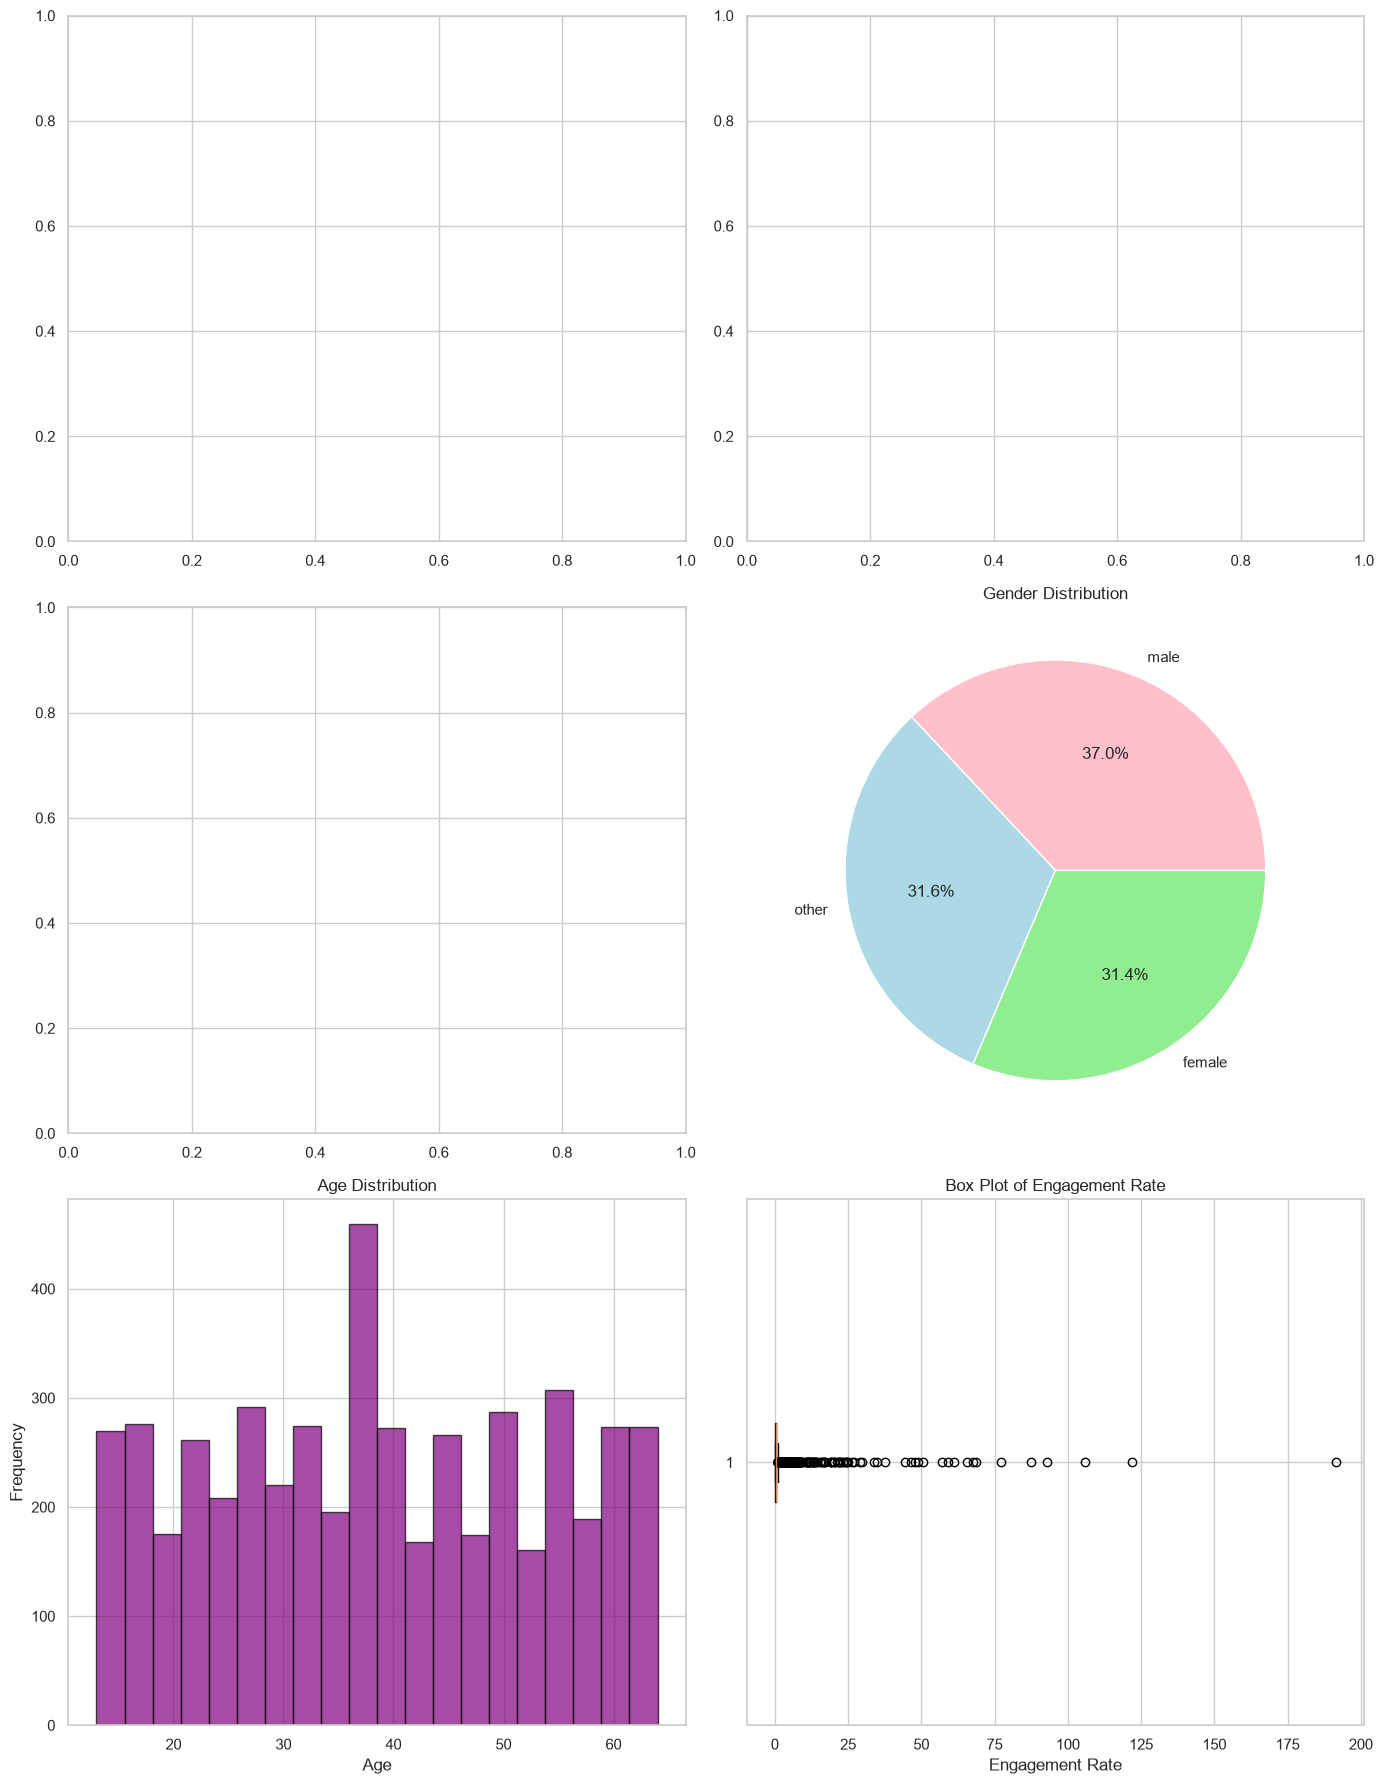

In [21]:
# Create a multi-plot layout figure for Matplotlib plots
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# 1. Matplotlib: Scatter (likes vs impressions)
if {'likes', 'impressions'}.issubset(df.columns):
    axes[0, 0].scatter(df['impressions'], df['likes'], alpha=0.5, color='teal')
    axes[0, 0].set_title('Likes vs Impressions')
    axes[0, 0].set_xlabel('Impressions')
    axes[0, 0].set_ylabel('Likes')

# 2. Matplotlib: Line (daily engagement trend)
if {'post_date', 'engagement_score'}.issubset(df.columns):
    daily_trend = df.groupby('post_date')['engagement_score'].mean()
    axes[0, 1].plot(daily_trend.index, daily_trend.values, color='coral', marker='o', linestyle='-')
    axes[0, 1].set_title('Daily Engagement Trend')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Avg Engagement Score')
    plt.xticks(rotation=45)

# 3. Matplotlib: Bar (posts by category)
if 'category' in df.columns:
    cat_counts = df['category'].value_counts()
    axes[1, 0].bar(cat_counts.index, cat_counts.values, color='skyblue')
    axes[1, 0].set_title('Posts by Category')
    axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Matplotlib: Pie (gender distribution)
if 'gender' in df.columns:
    gender_counts = df['gender'].value_counts()
    axes[1, 1].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', colors=['pink', 'lightblue', 'lightgreen'])
    axes[1, 1].set_title('Gender Distribution')

# 5. Matplotlib: Histogram (age)
if 'age' in df.columns:
    axes[2, 0].hist(df['age'].dropna(), bins=20, color='purple', alpha=0.7, edgecolor='black')
    axes[2, 0].set_title('Age Distribution')
    axes[2, 0].set_xlabel('Age')
    axes[2, 0].set_ylabel('Frequency')

# 6. Matplotlib: Box (engagement rate)
if 'engagement_rate' in df.columns:
    axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='orange'))
    axes[2, 1].set_title('Box Plot of Engagement Rate')
    axes[2, 1].set_xlabel('Engagement Rate')

plt.tight_layout()
plt.show()

C:\Users\ACER\AppData\Local\Temp\ipykernel_19504\176891960.py:42: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='orange'))


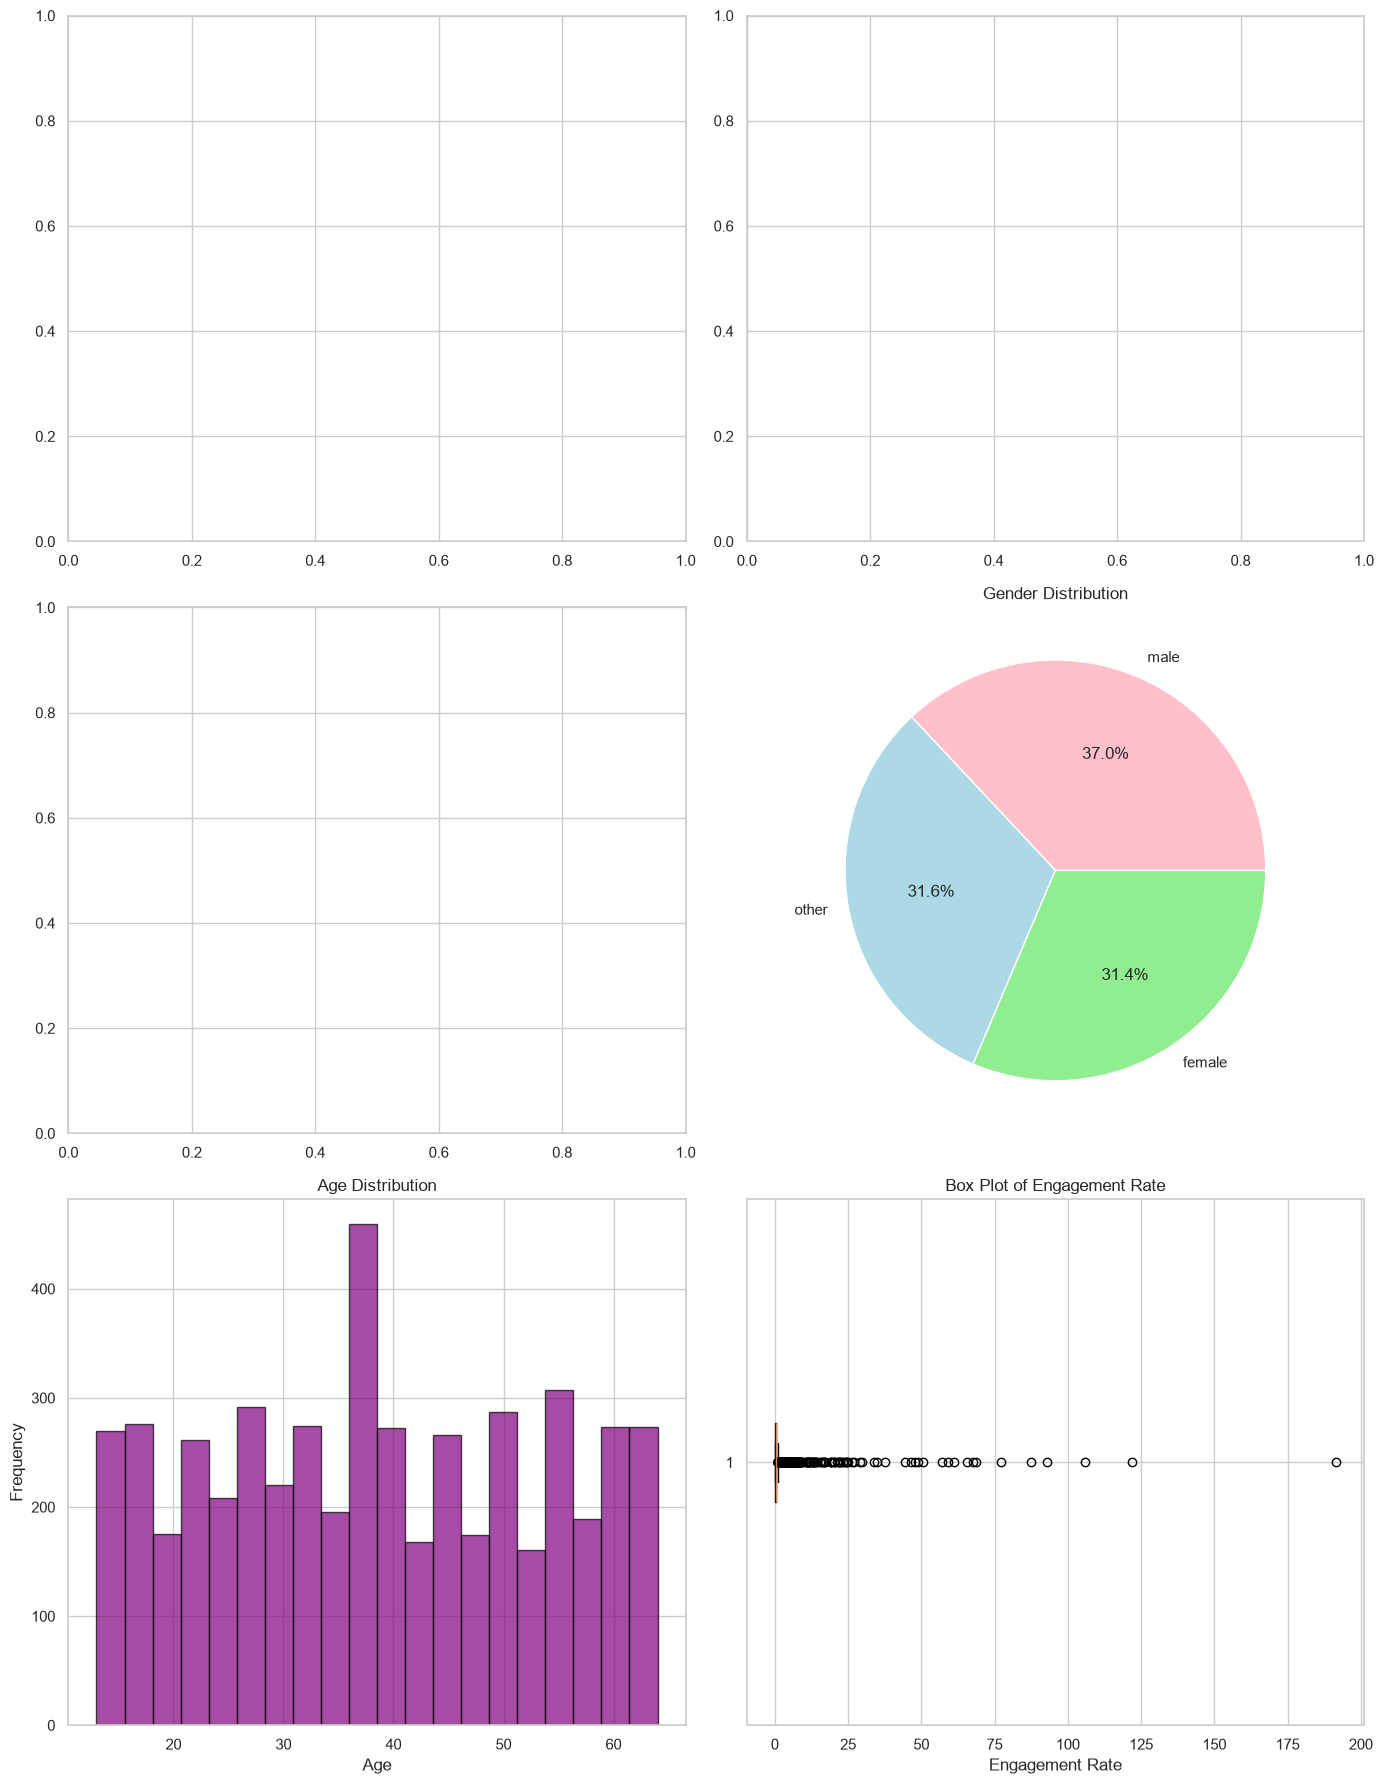

In [22]:
# Create a multi-plot layout figure for Matplotlib plots
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# 1. Matplotlib: Scatter (likes vs impressions)
if {'likes', 'impressions'}.issubset(df.columns):
    axes[0, 0].scatter(df['impressions'], df['likes'], alpha=0.5, color='teal')
    axes[0, 0].set_title('Likes vs Impressions')
    axes[0, 0].set_xlabel('Impressions')
    axes[0, 0].set_ylabel('Likes')

# 2. Matplotlib: Line (daily engagement trend)
if {'post_date', 'engagement_score'}.issubset(df.columns):
    daily_trend = df.groupby('post_date')['engagement_score'].mean()
    axes[0, 1].plot(daily_trend.index, daily_trend.values, color='coral', marker='o', linestyle='-')
    axes[0, 1].set_title('Daily Engagement Trend')
    axes[0, 1].set_xlabel('Date')
    axes[0, 1].set_ylabel('Avg Engagement Score')
    plt.xticks(rotation=45)

# 3. Matplotlib: Bar (posts by category)
if 'category' in df.columns:
    cat_counts = df['category'].value_counts()
    axes[1, 0].bar(cat_counts.index, cat_counts.values, color='skyblue')
    axes[1, 0].set_title('Posts by Category')
    axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Matplotlib: Pie (gender distribution)
if 'gender' in df.columns:
    gender_counts = df['gender'].value_counts()
    axes[1, 1].pie(gender_counts.values, labels=gender_counts.index, autopct='%1.1f%%', colors=['pink', 'lightblue', 'lightgreen'])
    axes[1, 1].set_title('Gender Distribution')

# 5. Matplotlib: Histogram (age)
if 'age' in df.columns:
    axes[2, 0].hist(df['age'].dropna(), bins=20, color='purple', alpha=0.7, edgecolor='black')
    axes[2, 0].set_title('Age Distribution')
    axes[2, 0].set_xlabel('Age')
    axes[2, 0].set_ylabel('Frequency')

# 6. Matplotlib: Box (engagement rate)
if 'engagement_rate' in df.columns:
    axes[2, 1].boxplot(df['engagement_rate'].dropna(), vert=False, patch_artist=True, boxprops=dict(facecolor='orange'))
    axes[2, 1].set_title('Box Plot of Engagement Rate')
    axes[2, 1].set_xlabel('Engagement Rate')

plt.tight_layout()
plt.show()

In [26]:
# 12. Plotly Interactive Chart (Bubble/Scatter Chart: Impressions vs Likes sized by Shares)
if {'impressions', 'likes', 'shares', 'post_type'}.issubset(df.columns):
    fig_plotly = px.scatter(
        df.sample(n=min(1000, len(df)), random_state=42), 
        x="impressions", 
        y="likes", 
        size="shares", 
        color="post_type",
        hover_name="post_type",
        title="Interactive Scatter: Impressions vs Likes (Sized by Shares)" )
    fig_plotly.show()